In [26]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    StratifiedKFold
)

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    precision_recall_curve,
    average_precision_score
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

SEED = 42

In [27]:
file_path = Path("heart.csv")

if not file_path.exists():
    raise FileNotFoundError(
        "heart.csv not found. Place it in the notebook folder."
    )

df = pd.read_csv(file_path)

# Clean column names
df.columns = df.columns.str.strip().str.lower()

print("Dataset shape:", df.shape)
print("\nFirst five rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

Dataset shape: (1025, 14)

First five rows:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0



Column names:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']


In [28]:
# Support common target column names
target_candidates = ["target", "output", "heart_disease"]

target_col = next(
    (col for col in target_candidates if col in df.columns),
    None
)

if target_col is None:
    raise ValueError(
        "Target column not found. Expected target, output, "
        "or heart_disease."
    )

# Remove rows without a target
df = df.dropna(subset=[target_col]).copy()
  
# Convert target to numeric
df[target_col] = pd.to_numeric(
    df[target_col], errors="coerce"
)

df = df.dropna(subset=[target_col]).copy()

# Remove exact duplicate rows before splitting
df = df.drop_duplicates().reset_index(drop=True)

# Convert feature columns to numeric
feature_cols = [
    col for col in df.columns if col != target_col
]
for col in feature_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Replace infinite values with missing values
df[feature_cols] = df[feature_cols].replace(
    [np.inf, -np.inf], np.nan
)

# Remove features containing no usable values
empty_cols = [
    col for col in feature_cols if df[col].isna().all()
]

df = df.drop(columns=empty_cols)
feature_cols = [
    col for col in df.columns if col != target_col
]

# Check that target contains exactly 0 and 1
if set(df[target_col].unique()) != {0, 1}:
    raise ValueError(
        f"Expected binary target values 0 and 1. "
        f"Found: {sorted(df[target_col].unique())}"
    )

df[target_col] = df[target_col].astype(int)

X = df[feature_cols].copy()
y = df[target_col].copy()

print("Cleaned dataset shape:", df.shape)
print("\nMissing values per feature:")
print(X.isna().sum())

print("\nClass distribution:")
print(y.value_counts().sort_index())

print("\nClass proportions:")
print(y.value_counts(normalize=True).sort_index().round(3))

Cleaned dataset shape: (302, 14)

Missing values per feature:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
dtype: int64

Class distribution:
target
0    138
1    164
Name: count, dtype: int64

Class proportions:
target
0    0.457
1    0.543
Name: proportion, dtype: float64


In [29]:
# First: 60% train and 40% temporary data
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.40,
    random_state=SEED,
    stratify=y
)

# Second: split temporary data equally into validation and test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

print("Training rows:", len(X_train))
print("Validation rows:", len(X_val))
print("Test rows:", len(X_test))

print("\nTraining proportion:", round(len(X_train) / len(X), 3))
print("Validation proportion:", round(len(X_val) / len(X), 3))
print("Test proportion:", round(len(X_test) / len(X), 3))

Training rows: 181
Validation rows: 60
Test rows: 61

Training proportion: 0.599
Validation proportion: 0.199
Test proportion: 0.202


In [30]:
def create_pipeline(classifier):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", classifier)
    ])

In [31]:
logistic_model = create_pipeline(
    LogisticRegression(
        max_iter=5000,
        random_state=SEED
    )
)
logistic_model.fit(X_train, y_train)

logistic_val_pred = logistic_model.predict(X_val)

print("Logistic Regression — Validation Results")
print("Accuracy:", round(
    accuracy_score(y_val, logistic_val_pred), 4
))
print("Precision:", round(
    precision_score(y_val, logistic_val_pred, zero_division=0), 4
))
print("Recall / Sensitivity:", round(
    recall_score(y_val, logistic_val_pred, zero_division=0), 4
))
print("F1-score:", round(
    f1_score(y_val, logistic_val_pred, zero_division=0), 4
))
                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                  
print("\nClassification report:")
print(classification_report(
    y_val, logistic_val_pred, zero_division=0
))

Logistic Regression — Validation Results
Accuracy: 0.7833
Precision: 0.8333
Recall / Sensitivity: 0.7576
F1-score: 0.7937

Classification report:
              precision    recall  f1-score   support

           0       0.73      0.81      0.77        27
           1       0.83      0.76      0.79        33

    accuracy                           0.78        60
   macro avg       0.78      0.79      0.78        60
weighted avg       0.79      0.78      0.78        60



In [32]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

linear_param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10, 100],
    "classifier__class_weight": [None, "balanced"]
}

rbf_param_grid = {
    "classifier__C": [0.1, 1, 10, 100],
    "classifier__gamma": ["scale", 0.001, 0.01, 0.1, 1],
    "classifier__class_weight": [None, "balanced"]
}

In [33]:
linear_pipeline = create_pipeline(
    SVC(kernel="linear")
)

linear_search = GridSearchCV(
    estimator=linear_pipeline,
    param_grid=linear_param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    refit=True
)

linear_search.fit(X_train, y_train)

best_linear_svm = linear_search.best_estimator_

print("Best Linear SVM parameters:")
print(linear_search.best_params_)

print("\nBest Linear SVM mean CV F1:")
print(round(linear_search.best_score_, 4))

Best Linear SVM parameters:
{'classifier__C': 0.01, 'classifier__class_weight': 'balanced'}

Best Linear SVM mean CV F1:
0.8585


In [34]:
rbf_pipeline = create_pipeline(
    SVC(kernel="rbf")
)

rbf_search = GridSearchCV(
    estimator=rbf_pipeline,
    param_grid=rbf_param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    refit=True
)

rbf_search.fit(X_train, y_train)

best_rbf_svm = rbf_search.best_estimator_

print("Best RBF SVM parameters:")
print(rbf_search.best_params_)

print("\nBest RBF SVM mean CV F1:")
print(round(rbf_search.best_score_, 4))

Best RBF SVM parameters:
{'classifier__C': 10, 'classifier__class_weight': None, 'classifier__gamma': 0.001}

Best RBF SVM mean CV F1:
0.8582


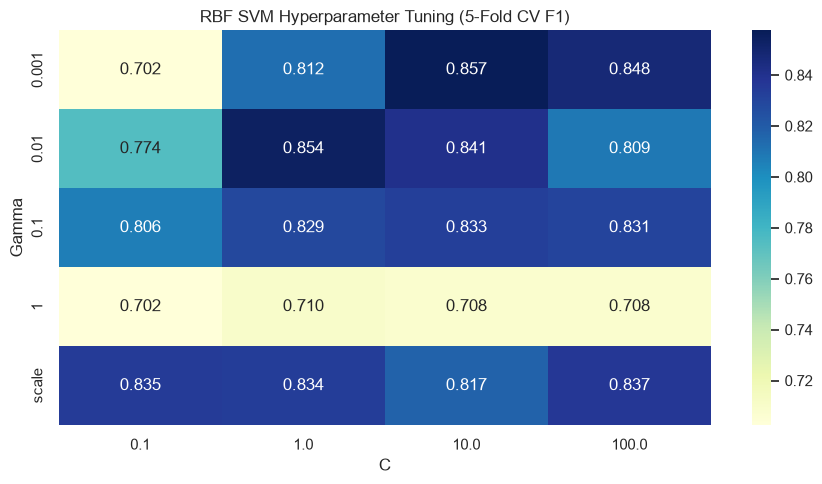

In [35]:
# RBF SVM: C and gamma performance heatmap

rbf_results = pd.DataFrame(rbf_search.cv_results_)

rbf_results["C"] = rbf_results[
    "param_classifier__C"
].astype(float)

rbf_results["gamma"] = rbf_results[
    "param_classifier__gamma"
].astype(str)

heatmap_data = rbf_results.pivot_table(
    index="gamma",
    columns="C",
    values="mean_test_score",
    aggfunc="mean"
)

plt.figure(figsize=(9, 5))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".3f",
    cmap="YlGnBu"
)

plt.title("RBF SVM Hyperparameter Tuning (5-Fold CV F1)")
plt.xlabel("C")
plt.ylabel("Gamma")
plt.tight_layout()
plt.show()

In [36]:
def calculate_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_true, y_pred, zero_division=0
        )
    }


models = {
    "Logistic Regression": logistic_model,
    "Linear SVM": best_linear_svm,
    "RBF SVM": best_rbf_svm
}

comparison = []

for name, model in models.items():
    predictions = model.predict(X_val)

    row = {"Model": name}
    row.update(calculate_metrics(y_val, predictions))
    comparison.append(row)

comparison_df = pd.DataFrame(comparison)

display(
    comparison_df.round(4).sort_values(
        "F1-score", ascending=False
    )
)

,Model,Accuracy,Precision,Recall,F1-score
1,Linear SVM,0.8167,0.8235,0.8485,0.8358
2,RBF SVM,0.8167,0.8235,0.8485,0.8358
0,Logistic Regression,0.7833,0.8333,0.7576,0.7937


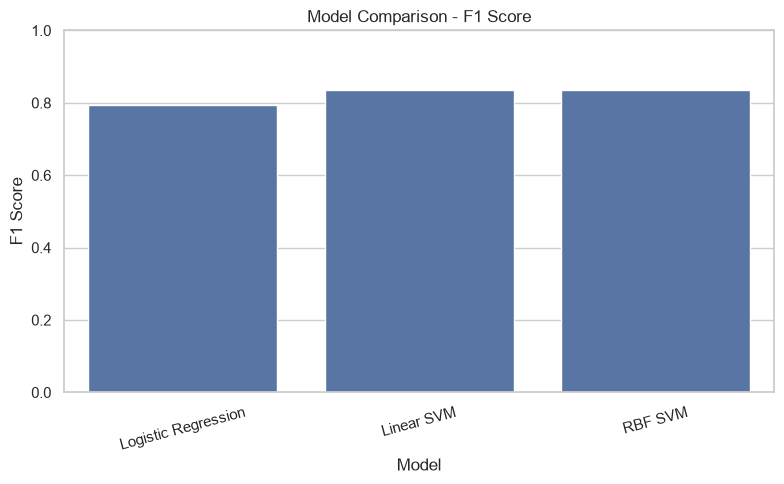

In [37]:
# Model Comparison Bar Chart

plt.figure(figsize=(8, 5))

sns.barplot(
    data=comparison_df,
    x="Model",
    y="F1-score"
)

plt.title("Model Comparison - F1 Score")
plt.xlabel("Model")
plt.ylabel("F1 Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [38]:
svm_models = {
    "Linear SVM": best_linear_svm,
    "RBF SVM": best_rbf_svm
}

svm_validation_results = {}

for name, model in svm_models.items():
    predictions = model.predict(X_val)
    svm_validation_results[name] = f1_score(
        y_val, predictions, zero_division=0
    )

best_svm_name = max(
    svm_validation_results,
    key=svm_validation_results.get
)

best_svm = svm_models[best_svm_name]

print("Selected SVM:", best_svm_name)
print(
    "Validation F1:",
    round(svm_validation_results[best_svm_name], 4)
)

Selected SVM: Linear SVM
Validation F1: 0.8358


In [39]:
from sklearn.metrics import recall_score, precision_score, f1_score

val_scores = best_svm.decision_function(X_val)

threshold_candidates = np.unique(
    np.concatenate([
        val_scores,
        [val_scores.min() - 1e-6,
         val_scores.max() + 1e-6]
    ])
)

threshold_results = []

for threshold in threshold_candidates:
    val_pred = (val_scores >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, val_pred, labels=[0, 1]
    ).ravel()

    sensitivity = recall_score(
        y_val, val_pred, zero_division=0
    )

    specificity = (
        tn / (tn + fp) if (tn + fp) > 0 else 0
    )

    precision = precision_score(
        y_val, val_pred, zero_division=0
    )

    f1 = f1_score(
        y_val, val_pred, zero_division=0
    )

    threshold_results.append({
        "Threshold": threshold,
        "Sensitivity": sensitivity,
        "Specificity": specificity,
        "Precision": precision,
        "F1-score": f1
    })

threshold_df = pd.DataFrame(threshold_results)

target_sensitivity = 0.90

eligible = threshold_df[
    threshold_df["Sensitivity"] >= target_sensitivity
]

if not eligible.empty:
    # Among thresholds reaching the target sensitivity,
    # prefer the highest specificity.
    selected_row = eligible.sort_values(
        ["Specificity", "Precision", "F1-score"],   
        ascending=False
    ).iloc[0]
else:
    # If the target is unattainable, prefer highest sensitivity.
    selected_row = threshold_df.sort_values(
        ["Sensitivity", "Specificity", "F1-score"],
        ascending=False
    ).iloc[0]

selected_threshold = float(selected_row["Threshold"])

print("Selected threshold:", round(selected_threshold, 4))
print("Validation sensitivity:", round(
    selected_row["Sensitivity"], 4
))
print("Validation specificity:", round(
    selected_row["Specificity"], 4
))
print("Validation precision:", round(
    selected_row["Precision"], 4
))
print("Validation F1-score:", round(
    selected_row["F1-score"], 4
))

Selected threshold: -0.215
Validation sensitivity: 0.9091
Validation specificity: 0.7778
Validation precision: 0.8333
Validation F1-score: 0.8696


In [40]:
default_val_pred = (val_scores >= 0.0).astype(int)

adjusted_val_pred = (
    val_scores >= selected_threshold
).astype(int)

print("DEFAULT THRESHOLD: 0.0")
print(confusion_matrix(
    y_val, default_val_pred, labels=[0, 1]
))
print(classification_report(
    y_val, default_val_pred, zero_division=0
))

print("\nADJUSTED THRESHOLD:", round(selected_threshold, 4))
print(confusion_matrix(
    y_val, adjusted_val_pred, labels=[0, 1]
))
print(classification_report(
    y_val, adjusted_val_pred, zero_division=0
))

DEFAULT THRESHOLD: 0.0
[[21  6]
 [ 5 28]]
              precision    recall  f1-score   support

           0       0.81      0.78      0.79        27
           1       0.82      0.85      0.84        33

    accuracy                           0.82        60
   macro avg       0.82      0.81      0.81        60
weighted avg       0.82      0.82      0.82        60


ADJUSTED THRESHOLD: -0.215
[[21  6]
 [ 3 30]]
              precision    recall  f1-score   support

           0       0.88      0.78      0.82        27
           1       0.83      0.91      0.87        33

    accuracy                           0.85        60
   macro avg       0.85      0.84      0.85        60
weighted avg       0.85      0.85      0.85        60



In [41]:
linear_classifier = best_linear_svm.named_steps["classifier"]

coefficients = linear_classifier.coef_[0]

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": coefficients,
    "Importance": np.abs(coefficients)
})

feature_importance = feature_importance.sort_values(
    "Importance", ascending=False
)

print("Top 5 features by absolute coefficient:")
display(feature_importance.head(5).round(4))

Top 5 features by absolute coefficient:


,Feature,Coefficient,Importance
2,cp,0.3100,0.3100
8,exang,-0.2461,0.2461
11,ca,-0.2137,0.2137
9,oldpeak,-0.2008,0.2008
10,slope,0.1825,0.1825


In [42]:
# Compare top 5 SVM features with general medical knowledge

top_5_features = feature_importance.head(5).copy()

medical_knowledge = {
    "age": "Age is associated with heart disease risk.",
    "sex": "Sex is associated with differences in heart disease risk.",
    "cp": "Chest pain type can provide clinically relevant information.",
    "trestbps": "High resting blood pressure is a known risk factor.",
    "chol": "High cholesterol can contribute to cardiovascular risk.",
    "fbs": "Elevated fasting blood sugar may relate to metabolic risk.",
    "restecg": "Resting ECG findings can provide cardiac information.",
    "thalach": "Maximum heart rate achieved can be clinically relevant.",
    "exang": "Exercise-induced angina can be clinically relevant.",
    "oldpeak": "ST depression during exercise can provide cardiac information.",
    "slope": "The exercise ST-segment slope can be clinically relevant.",
    "ca": "Major vessels observed can provide relevant diagnostic information.",
    "thal": "The thalassemia-related dataset category may carry predictive information."
}

top_5_features["Medical Context"] = (
    top_5_features["Feature"]
    .map(medical_knowledge)
    .fillna("Check the feature definition in the dataset.")
)

display(top_5_features.round(4))

,Feature,Coefficient,Importance,Medical Context
2,cp,0.3100,0.3100,Chest pain type can provide clinically relevan...
8,exang,-0.2461,0.2461,Exercise-induced angina can be clinically rele...
11,ca,-0.2137,0.2137,Major vessels observed can provide relevant di...
9,oldpeak,-0.2008,0.2008,ST depression during exercise can provide card...
10,slope,0.1825,0.1825,The exercise ST-segment slope can be clinicall...


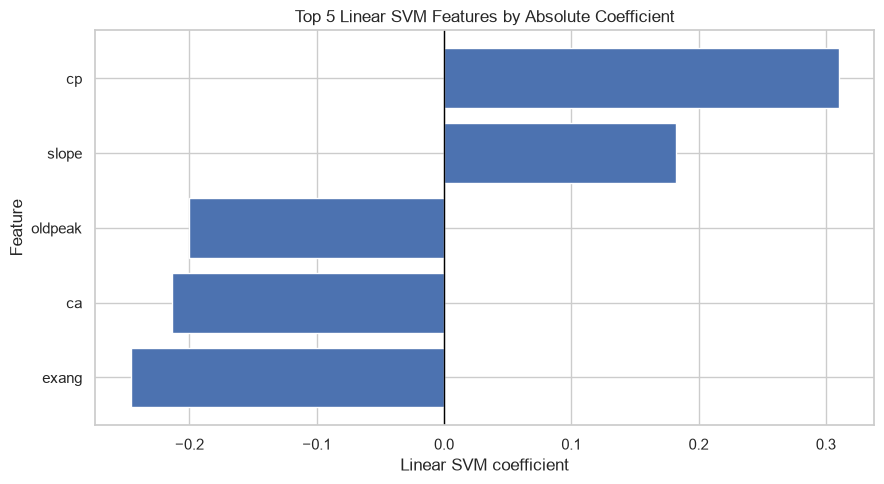

In [43]:
top_5 = feature_importance.head(5).sort_values(
    "Coefficient"
)

plt.figure(figsize=(9, 5))

plt.barh(
    top_5["Feature"],
    top_5["Coefficient"]
)

plt.axvline(0, color="black", linewidth=1)

plt.xlabel("Linear SVM coefficient")
plt.ylabel("Feature")
plt.title("Top 5 Linear SVM Features by Absolute Coefficient")
plt.tight_layout()
plt.show()

In [44]:
test_scores = best_svm.decision_function(X_test)

test_pred = (
    test_scores >= selected_threshold
).astype(int)

print("Selected model:", best_svm_name)
print("Selected threshold:", round(selected_threshold, 4))

print("\nTest Accuracy:",
      round(accuracy_score(y_test, test_pred), 4))

print("Test Precision:",
      round(precision_score(
          y_test, test_pred, zero_division=0
      ), 4))

print("Test Recall / Sensitivity:",
      round(recall_score(
          y_test, test_pred, zero_division=0
      ), 4))

print("Test F1-score:",
      round(f1_score(
          y_test, test_pred, zero_division=0
      ), 4))

print("\nTest confusion matrix:")
cm = confusion_matrix(y_test, test_pred, labels=[0, 1])
print(cm)

print("\nClassification report:")
print(classification_report(
    y_test, test_pred, zero_division=0
))

Selected model: Linear SVM
Selected threshold: -0.215

Test Accuracy: 0.8689
Test Precision: 0.8378
Test Recall / Sensitivity: 0.9394
Test F1-score: 0.8857

Test confusion matrix:
[[22  6]
 [ 2 31]]

Classification report:
              precision    recall  f1-score   support

           0       0.92      0.79      0.85        28
           1       0.84      0.94      0.89        33

    accuracy                           0.87        61
   macro avg       0.88      0.86      0.87        61
weighted avg       0.87      0.87      0.87        61



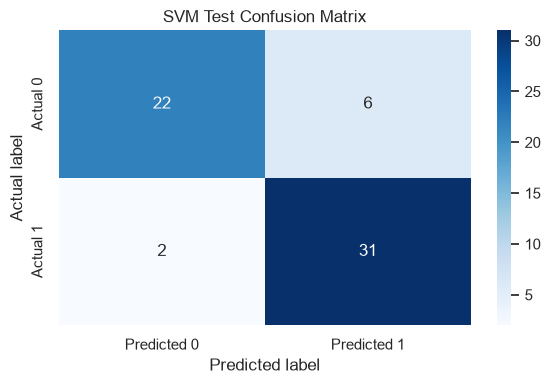

In [45]:
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted 0", "Predicted 1"],
    yticklabels=["Actual 0", "Actual 1"]
)

plt.title("SVM Test Confusion Matrix")
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.tight_layout()
plt.show()

In [46]:
tn, fp, fn, tp = confusion_matrix(
    y_test, test_pred, labels=[0, 1]
).ravel()

print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

print("Sensitivity:", tp / (tp + fn) if tp + fn > 0 else 0)
print("Specificity:", tn / (tn + fp) if tn + fp > 0 else 0)

True Negatives: 22
False Positives: 6
False Negatives: 2
True Positives: 31
Sensitivity: 0.9393939393939394
Specificity: 0.7857142857142857


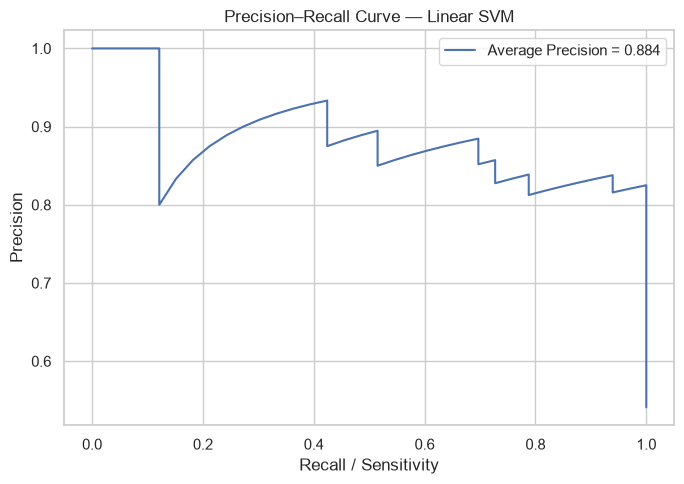

Average Precision: 0.8842


In [47]:
precision_values, recall_values, _ = precision_recall_curve(
    y_test, test_scores
)

average_precision = average_precision_score(
    y_test, test_scores
)

plt.figure(figsize=(7, 5))

plt.plot(
    recall_values,
    precision_values,
    label=f"Average Precision = {average_precision:.3f}"
)

plt.xlabel("Recall / Sensitivity")
plt.ylabel("Precision")
plt.title(f"Precision–Recall Curve — {best_svm_name}")
plt.legend()
plt.tight_layout()
plt.show()

print("Average Precision:", round(average_precision, 4))